In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

In [30]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

First 5 records
Number of rows and columns

In [31]:
print("First 5 Records:")
display(df.head())


First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Data types of all columns

In [32]:
print("\nData Types:")
print(df.dtypes)


Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


Number of missing values in each column

In [33]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Perform the required data preprocessing:

Convert TotalCharges into a suitable numerical datatype.

In [34]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

Handle missing values appropriately.

In [35]:
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)


Remove customerID

In [36]:
df = df.drop("customerID", axis=1)

Encode all categorical variables.

In [37]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

Encode the target variable Churn

In [38]:
df = pd.get_dummies(df, drop_first=True)

In [39]:
print("\nAfter Preprocessing:")
print(df.head())


After Preprocessing:
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  Churn  gender_Male  \
0              0       1           29.85         29.85      0        False   
1              0      34           56.95       1889.50      0         True   
2              0       2           53.85        108.15      1         True   
3              0      45           42.30       1840.75      0         True   
4              0       2           70.70        151.65      1        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False           False              True   

   MultipleLines_No phone service  ...  StreamingTV_No internet service  \
0                            True  ...                            False   
1                           False  ...        

In [40]:
print("\nRemaining Missing Values:")
print(df.isnull().sum().sum())



Remaining Missing Values:
0


Perform basic EDA and identify
The percentage of customers who have churned

In [41]:
churn_percentage = df["Churn"].mean() * 100

print("\nPercentage of Customers Churned:",
      round(churn_percentage, 2), "%")


Percentage of Customers Churned: 26.54 %


The average MonthlyCharges for churned and non-churned customers.

In [42]:
print("\nAverage MonthlyCharges:")
print(df.groupby("Churn")["MonthlyCharges"].mean())


Average MonthlyCharges:
Churn
0    61.265124
1    74.441332
Name: MonthlyCharges, dtype: float64


The average Tenure for churned and non-churned customers.


In [43]:
print("\nAverage Tenure:")
print(
    df.groupby("Churn")["tenure"].mean()
)


Average Tenure:
Churn
0    37.569965
1    17.979133
Name: tenure, dtype: float64


Prepare the feature matrix X and target y.

In [44]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

Train a Logistic Regression model on the training data.

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


Predict churn for the test dataset.
Train a Logistic Regression model on the training data.

In [46]:
lr_model = LogisticRegression(max_iter=2000, solver="liblinear")
lr_model.fit(X_train, y_train)

# Predict churn for test data
y_pred = lr_model.predict(X_test)

print("Predicted Churn:")
print(y_pred)


Predicted Churn:
[0 1 0 ... 0 0 0]


Evaluate the model using:
Accuracy
Precision
Recall
F1-score
Confusion Matrix

In [47]:
print("\nAccuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1-Score:",
      f1_score(y_test, y_pred))



Accuracy: 0.8041163946061036
Precision: 0.657051282051282
Recall: 0.5481283422459893
F1-Score: 0.597667638483965


Identify whether the model performs better in identifying Churn = Yes or Churn = No using the classification report.

In [48]:
report = classification_report(
    y_test, y_pred,
    target_names=["Churn = No", "Churn = Yes"],
    output_dict=True
)

print("Churn = No Recall:", report["Churn = No"]["recall"])
print("Churn = Yes Recall:", report["Churn = Yes"]["recall"])

Churn = No Recall: 0.8966183574879227
Churn = Yes Recall: 0.5481283422459893


Plot the Feature Importance of the Random Forest model and display the top 10 most important features.

In [49]:
rf_features = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

rf_features = rf_features.sort_values(
    "Importance",
    ascending=False
)

top10_rf = rf_features.head(10)

print("\nTop 10 Random Forest Features:")
print(top10_rf)


Top 10 Random Forest Features:
                           Feature  Importance
3                     TotalCharges    0.189701
1                           tenure    0.175710
2                   MonthlyCharges    0.172418
10     InternetService_Fiber optic    0.036053
28  PaymentMethod_Electronic check    0.035302
25               Contract_Two year    0.030435
13              OnlineSecurity_Yes    0.029238
4                      gender_Male    0.027423
26            PaperlessBilling_Yes    0.025295
5                      Partner_Yes    0.024209


Compare the performance of Logistic Regression and Random Forest using:
Accuracy
Precision
Recall
F1-score

In [50]:
# Top 5 features influencing churn

feature_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_[0]
})

# Take absolute values of coefficients
feature_coefficients["Absolute_Coefficient"] = abs(
    feature_coefficients["Coefficient"]
)

# Sort and select top 5
top_5_features = feature_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).head(5)

print("Top 5 Features Influencing Churn:")
print(top_5_features)

Top 5 Features Influencing Churn:
                        Feature  Coefficient  Absolute_Coefficient
25            Contract_Two year    -1.193878              1.193878
10  InternetService_Fiber optic     0.743913              0.743913
24            Contract_One year    -0.659033              0.659033
7              PhoneService_Yes    -0.481484              0.481484
13           OnlineSecurity_Yes    -0.415860              0.415860


Random Forest Classifier 

Use the preprocessed dataset from Question 1 and divide it into 80% training and 20% testing data.
Train a Random Forest Classifier with:
n_estimators = 100
random_state = 42

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Random Forest Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Predict the churn status for the test dataset.
Evaluate the Random Forest model using:
Accuracy
Precision
Recall
F1-score
Confusion Matrix

In [55]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict test data
y_pred_rf = rf.predict(X_test)

# Evaluation
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1-score :", f1_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))


# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict test data
rf_pred = rf_model.predict(X_test)

Accuracy : 0.7892122072391767
Precision: 0.6428571428571429
Recall   : 0.4584450402144772
F1-score : 0.5352112676056338
Confusion Matrix:
 [[941  95]
 [202 171]]


plot the Feature Importance of the Random Forest model and display the top 10 most important features.
Compare the performance of Logistic Regression and Random Forest using:
Accuracy
Precision
Recall
F1-score

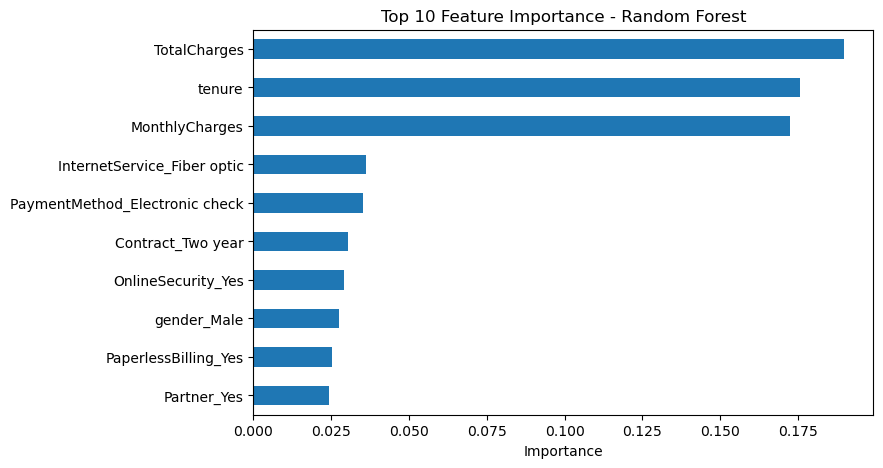

In [56]:
# Top 10 Random Forest Feature Importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10)

importance.plot(kind="barh", figsize=(8,5))
plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

Identify which model has a higher recall for the Churn = Yes class.
Using the Random Forest predictions, identify the following:
Number of customers correctly predicted as churned.
Number of customers incorrectly predicted as churned.
Number of customers who actually churned but were predicted as non-churned.

In [57]:
# Recall comparison for Churn = Yes
lr_recall = recall_score(y_test, y_pred)
rf_recall = recall_score(y_test, rf_pred)

print("Logistic Regression Recall:", lr_recall)
print("Random Forest Recall:", rf_recall)

if lr_recall > rf_recall:
    print("Logistic Regression has higher recall for Churn = Yes")
else:
    print("Random Forest has higher recall for Churn = Yes")


# Random Forest confusion matrix
TN, FP, FN, TP = confusion_matrix(y_test, rf_pred).ravel()

print("\nCorrectly predicted as churned (TP):", TP)
print("Incorrectly predicted as churned (FP):", FP)
print("Actually churned but predicted as non-churned (FN):", FN)

Logistic Regression Recall: 0.21715817694369974
Random Forest Recall: 0.4584450402144772
Random Forest has higher recall for Churn = Yes

Correctly predicted as churned (TP): 171
Incorrectly predicted as churned (FP): 95
Actually churned but predicted as non-churned (FN): 202


Create a confusion matrix heatmap for the Random Forest model.

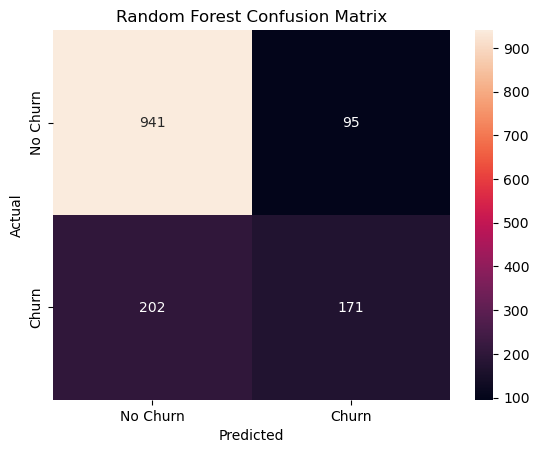

In [58]:
# Random Forest Confusion Matrix Heatmap

cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

Based on the feature importance results, identify the three most important customer characteristics 
associated with the model's churn predictions and briefly explain what the results indicate.

In [59]:
# Top 3 most important customer characteristics

top3 = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(3)

print("Top 3 Important Customer Characteristics:")
print(top3)

print("\nExplanation:")
for feature, importance in top3.items():
    print(f"{feature}: Importance = {importance:.4f}")
    print("This feature has a strong influence on the Random Forest's churn predictions.\n")

Top 3 Important Customer Characteristics:
TotalCharges      0.189701
tenure            0.175710
MonthlyCharges    0.172418
dtype: float64

Explanation:
TotalCharges: Importance = 0.1897
This feature has a strong influence on the Random Forest's churn predictions.

tenure: Importance = 0.1757
This feature has a strong influence on the Random Forest's churn predictions.

MonthlyCharges: Importance = 0.1724
This feature has a strong influence on the Random Forest's churn predictions.

